# Drosophila embryos: Model Training

[Project overview](../README.md) · [01 Data preparation](./01_data_preparation.ipynb) · [02 DLPFC](./02_DLPFC.ipynb) · [03 Drosophila embryos](./03_Drosophila%20embryos.ipynb) · [04 Embryo](./04_Embryo.ipynb) · [05 Liver cancer](./05_liver_cancer.ipynb)

This tutorial trains K-SPADA on Drosophila embryo reference samples, then predicts query sample 6 and displays known and predicted spatial labels.

Training graph: `../../data/fly/h14-16_2_6_10_14_train_valid_CGraph_k_1.h5ad`. Training samples: **1, 3, 4, 5, 7, 8, 9, 11, 12, 13, 15**. Validation sample: **16**. The notebook trains for **10 epochs**. The current code selects `mouse_gobp`; this configuration is preserved for this execution.

Run this notebook from `tutorials/` with **Python (KSPADA_env @ d05 GPU 3)**. All documentation paths are relative to this directory. Existing code cells, input paths, and model parameters are preserved. Training uses GPU 3; the current prediction implementation runs on CPU.


In [ ]:
from pathlib import Path
import anndata as ad
import torch
import KSPADA

PROJECT_ROOT = Path("..").resolve()
DATA_DIR = Path("../../data/fly").resolve()
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "Drosophila_embryos" / "model_training"
TRAIN_VALID_H5AD = DATA_DIR / "h14-16_2_6_10_14_train_valid_CGraph_k_1.h5ad"
PROJECT_NAME = "Drosophila_2_6_10_14"

TRAIN_SAMPLES = ['1', '3', '4', '5', '7', '8', '9', '11', '12', '13', '15']
VALIDATION_SAMPLES = ['16']
PATHWAY_NAME = "mouse_gobp"
LABEL_NAME = "Celltype"
MAX_GENES_PER_PATHWAY = 300
MAX_PATHWAY_TOKENS = 300
MASK_RATIO = 0.015
UNANNOTATED_TOKENS = 1
STANDARD_BATCH_SIZE = 8
EMBEDDING_DIM = 48
TRANSFORMER_DEPTH = 2
ATTENTION_HEADS = 4
LEARNING_RATE = 0.001
WEIGHT_DECAY = 5e-5
EPOCHS = 10
FINAL_LEARNING_RATE_RATIO = 0.01
GRAPH_BATCH_SIZE = 16
SPATIAL_NEIGHBORS = 6
LAMBDA_REGULARIZATION = 0.00001
RANDOM_SEED = 1

## Step 1 — Select the GPU

**Execution result (2026-11-13):** CUDA was available on `d05`. The `KSPADA_env` kernel used physical GPU 3 (NVIDIA A100 80GB PCIe), exposed as `cuda:0`.


In [ ]:
if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable. Select a GPU-enabled KSPADA kernel before training.")

torch.cuda.set_device(0)
TRAINING_DEVICE = torch.device("cuda:0")

## Step 2 — Validate the prepared graph file

**Execution result:** input-file checks, required graph fields, and the expected sample split passed. The prepared graph contains **11,605 observations × 3,000 genes**.


In [ ]:
if not TRAIN_VALID_H5AD.is_file():
    raise FileNotFoundError(TRAIN_VALID_H5AD)

KSPADA.validate_cgraph_fields(TRAIN_VALID_H5AD, mode="train")
training_adata = ad.read_h5ad(TRAIN_VALID_H5AD, backed="r")
actual_samples = set(training_adata.obs["batch"].astype(str).unique())
expected_samples = set(TRAIN_SAMPLES + VALIDATION_SAMPLES)
training_adata.file.close()
if actual_samples != expected_samples:
    raise ValueError(
        f"Sample mismatch: expected {sorted(expected_samples)}, found {sorted(actual_samples)}"
    )

## Step 3 — Train the model

**Execution result:** all **10 training epochs** completed. The final progress output reports training accuracy **97.9%** and validation accuracy **54.1%** (rounded as printed by the original code). Checkpoint: `../outputs/Drosophila_embryos/model_training/Drosophila_2_6_10_14/model-9.pth`.


In [ ]:
model_directory = KSPADA.train_model(
    adata_input=TRAIN_VALID_H5AD,
    project=PROJECT_NAME,
    output_dir=OUTPUT_DIR,
    gmt_path=PATHWAY_NAME,
    label_name=LABEL_NAME,
    train_batches=TRAIN_SAMPLES,
    use_gcn=True,
    pre_weights="",
    max_g=MAX_GENES_PER_PATHWAY,
    max_gs=MAX_PATHWAY_TOKENS,
    mask_ratio=MASK_RATIO,
    n_unannotated=UNANNOTATED_TOKENS,
    batch_size=STANDARD_BATCH_SIZE,
    embed_dim=EMBEDDING_DIM,
    depth=TRANSFORMER_DEPTH,
    num_heads=ATTENTION_HEADS,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    epochs=EPOCHS,
    lrf=FINAL_LEARNING_RATE_RATIO,
    batch_size_gcn=GRAPH_BATCH_SIZE,
    neighbor=SPATIAL_NEIGHBORS,
    lambda_reg=LAMBDA_REGULARIZATION,
    random_seed=RANDOM_SEED,
)

batch_size_gcn: 16
lambda_reg: 1e-05
neighbor: 6
num_head: 4
depth: 2
embed_dim: 48
weight_decay: 5e-05
random_seed: 1
cuda:0
torch.Size([2, 62970])
torch.Size([2, 6660])
enhance:  torch.Size([2, 62970])
enhance:  torch.Size([2, 6660])


edge_index_train shape before merge: torch.Size([2, 235373])
edge_index_valid shape before merge: torch.Size([2, 27925])
edge_index_train shape after merge: torch.Size([2, 237243])
edge_index_valid shape after merge: torch.Size([2, 28072])


Mask loaded!
use_gcn:True
use_position_encode: False
embed_dim_heads: 48
num_heads: 4


Model builded!



  0%|          | 0/2484 [00:00<?, ?it/s]


[train epoch 0] loss: 2.231, acc: 0.204:   4%|▍         | 99/2484 [00:05<02:00, 19.75it/s]

... (220 outputs left out)


[train epoch 9] loss: 0.071, acc: 0.979: 100%|██████████| 2484/2484 [02:33<00:00, 16.14it/s]


  0%|          | 0/298 [00:00<?, ?it/s]


[valid epoch 9] loss: 6.595, acc: 0.541: 100%|██████████| 298/298 [00:01<00:00, 180.00it/s]

Training finished!


## Notes

- Replace the sample names with values present in the prepared graph file.
- Training and prediction must use the same embedding dimension, Transformer depth, attention-head count, and graph settings.

# Drosophila embryos: Prediction and Visualization

This continuation predicts query samples **2, 6, 10, 12** with the existing trained checkpoint. The training section and all code cells are preserved.

**Execution context:** the runner supplied `QUERY_H5AD` and the sample-specific `QUERY_SAMPLE` aliases required by the existing cells. It also set sample-specific `PREDICTION_H5AD` and `FIGURE_PREFIX` values before each prediction. These values are recorded in the prediction cell metadata; they are runtime context, not changes to the code cells.


In [ ]:
from pathlib import Path
import KSPADA

PROJECT_ROOT = Path("..").resolve()
DATA_DIR = Path("../../../../TOSICA-main/data/Fly3d").resolve()
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "Drosophila_embryos" / "prediction"
MODEL_DIR = PROJECT_ROOT / "outputs" / "Drosophila_embryos" / "model_training" / "Drosophila_2_6_10_14"
MODEL_WEIGHT_PATH = MODEL_DIR / "model-9.pth"

QUERY_SAMPLE = "12"
QUERY_H5AD = DATA_DIR / "fly_E14-16h_hvg_3000_query_12_path_scores_graph_k_1.h5ad"

REFERENCE_H5AD = Path("../../../../TOSICA-main/data/Fly3d/fly_E16-18h_hvg_3000.h5ad").resolve()
SECOND_REFERENCE_H5AD = Path("../../../../TOSICA-main/data/Fly3d/fly_E14-16h_hvg_3000.h5ad").resolve()
PREDICTION_H5AD = OUTPUT_DIR / "query_prediction.h5ad"
FIGURE_PREFIX = OUTPUT_DIR / "query_prediction_spatial"

PREDICTION_CUTOFF = 0.1
USE_GCN = True
UNANNOTATED_TOKENS = 1
PREDICTION_BATCH_SIZE = 50
EMBEDDING_DIM = 48
TRANSFORMER_DEPTH = 2
ATTENTION_HEADS = 4
POINT_SIZE = 150

## Step 1 — Validate input paths

**Execution result:** all 4 query inputs, the trained checkpoint, and plotting reference files were found. Each query has the same genes in the same order as the training input.


In [ ]:
for required_path in [MODEL_DIR, MODEL_WEIGHT_PATH, QUERY_H5AD, REFERENCE_H5AD, SECOND_REFERENCE_H5AD]:
    if not required_path.exists():
        raise FileNotFoundError(required_path)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Step 2 — Predict the query samples

**Execution result:** all configured queries completed. Accuracy was calculated after prediction by comparing against the existing `Celltype` column.

| Query sample | Observations | Accuracy | Prediction file |
| --- | ---: | ---: | --- |
| 2 | 549 | 63.57% | [h5ad](../outputs/Drosophila_embryos/prediction/query_prediction_2.h5ad) |
| 6 | 815 | 62.58% | [h5ad](../outputs/Drosophila_embryos/prediction/query_prediction_6.h5ad) |
| 10 | 1,248 | 63.54% | [h5ad](../outputs/Drosophila_embryos/prediction/query_prediction_10.h5ad) |
| 12 | 1,260 | 94.13% | [h5ad](../outputs/Drosophila_embryos/prediction/query_prediction_12.h5ad) |


In [ ]:
prediction_adata = KSPADA.predict_model(
    adata_input=QUERY_H5AD,
    model_dir=MODEL_DIR,
    model_weight_path=MODEL_WEIGHT_PATH,
    output_path=PREDICTION_H5AD,
    prediction_batches=[QUERY_SAMPLE],
    cutoff=PREDICTION_CUTOFF,
    use_gcn=USE_GCN,
    n_unannotated=UNANNOTATED_TOKENS,
    batch_size=PREDICTION_BATCH_SIZE,
    embed_dim=EMBEDDING_DIM,
    depth=TRANSFORMER_DEPTH,
    num_heads=ATTENTION_HEADS,
)

cpu
depth: 2
num_heads: 4
embed_dim: 48
use_gcn: True
prediction_mode: full_graph
neighbor: 6
edge_index shape: torch.Size([2, 7560])
edge_index after merge shape: torch.Size([2, 7661])
use_position_encode: False
embed_dim_heads: 48
num_heads: 4


## Step 3 — Create spatial plots

**Execution result:** each query has its own embedded spatial comparison in the corresponding plotting cell. All PNG (600 DPI), PDF, and SVG exports were checked.

| Query sample | PNG | PDF | SVG |
| --- | --- | --- | --- |
| 2 | [PNG](../outputs/Drosophila_embryos/prediction/query_prediction_spatial_2.png) | [PDF](../outputs/Drosophila_embryos/prediction/query_prediction_spatial_2.pdf) | [SVG](../outputs/Drosophila_embryos/prediction/query_prediction_spatial_2.svg) |
| 6 | [PNG](../outputs/Drosophila_embryos/prediction/query_prediction_spatial_6.png) | [PDF](../outputs/Drosophila_embryos/prediction/query_prediction_spatial_6.pdf) | [SVG](../outputs/Drosophila_embryos/prediction/query_prediction_spatial_6.svg) |
| 10 | [PNG](../outputs/Drosophila_embryos/prediction/query_prediction_spatial_10.png) | [PDF](../outputs/Drosophila_embryos/prediction/query_prediction_spatial_10.pdf) | [SVG](../outputs/Drosophila_embryos/prediction/query_prediction_spatial_10.svg) |
| 12 | [PNG](../outputs/Drosophila_embryos/prediction/query_prediction_spatial_12.png) | [PDF](../outputs/Drosophila_embryos/prediction/query_prediction_spatial_12.pdf) | [SVG](../outputs/Drosophila_embryos/prediction/query_prediction_spatial_12.svg) |


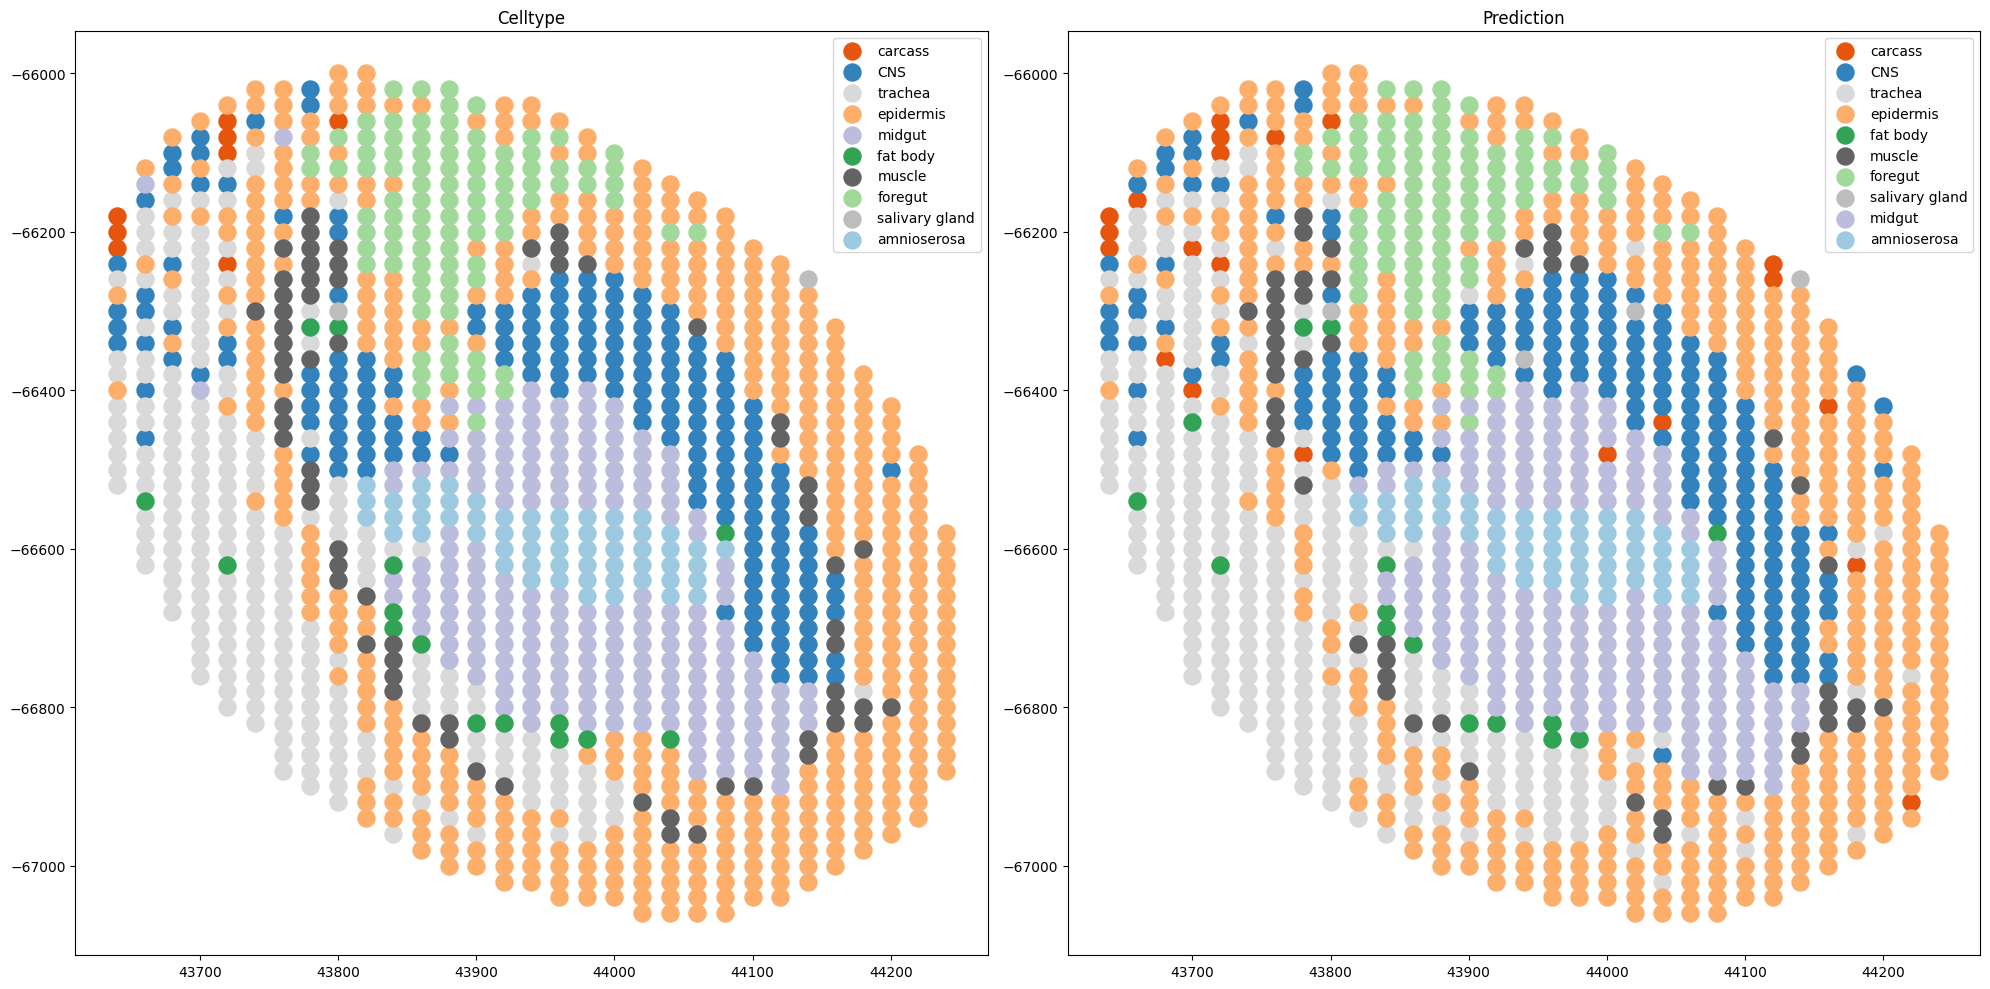

In [14]:
import anndata as ad
import matplotlib.pyplot as plt

# Match query_span_time.py by combining both developmental-stage labels.
first_reference = ad.read_h5ad(REFERENCE_H5AD, backed="r")
second_reference = ad.read_h5ad(SECOND_REFERENCE_H5AD, backed="r")
color_labels = sorted(set(first_reference.obs["Celltype"].unique()) | set(second_reference.obs["Celltype"].unique()))
first_reference.file.close()
second_reference.file.close()
color_map = plt.get_cmap("tab20c", len(color_labels))
label_colors = {label: color_map(index) for index, label in enumerate(color_labels)}

# Match the source script's spatial orientation and side-by-side comparison.
x_coordinates = prediction_adata.obs["x"]
y_coordinates = -prediction_adata.obs["y"]
celltypes = prediction_adata.obs["Celltype"].astype(str)
predictions = prediction_adata.obs["Prediction"].astype(str)
figure, axes = plt.subplots(1, 2, figsize=(20, 10))
for celltype in celltypes.unique():
    matching_cells = celltypes == celltype
    axes[0].scatter(x_coordinates[matching_cells], y_coordinates[matching_cells], color=label_colors[celltype], label=celltype, s=POINT_SIZE)
axes[0].legend()
axes[0].set_title("Celltype")
for prediction in predictions.unique():
    matching_cells = predictions == prediction
    axes[1].scatter(x_coordinates[matching_cells], y_coordinates[matching_cells], color=label_colors[prediction], label=prediction, s=POINT_SIZE)
axes[1].legend()
axes[1].set_title("Prediction")
plt.tight_layout()

# Preserve the tutorial's high-resolution raster and vector exports.
figure.savefig(FIGURE_PREFIX.with_suffix(".png"), dpi=600, bbox_inches="tight")
figure.savefig(FIGURE_PREFIX.with_suffix(".pdf"), bbox_inches="tight")
figure.savefig(FIGURE_PREFIX.with_suffix(".svg"), bbox_inches="tight")
plt.show()


## Notes

- Query genes must match the model gene names and gene order.
- Replace `QUERY_SAMPLE` with the value stored in `adata.obs["batch"]` for the query graph.